# Evaluación final, contraste de hipótesis y selección del mejor modelo

Se evalúan los 45 detectores seleccionados sobre el test oficial con defectos reales, sin reentrenar modelos, modificar umbrales ni seleccionar nuevas variantes

Las hipótesis H1–H3 comparan las variantes de cada modelo mediante validación sintética. La hipótesis H4 compara Autoencoder, PatchCore y Doble U-Net sobre las mismas 15 categorías del test real, utilizando métricas de detección, localización y eficiencia computacional

Esta evaluación permite identificar el método con mejor desempeño en el conjunto estudiado, sin asumir que los resultados se generalizan a otros entornos industriales

## Preparación del ambiente

In [16]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import wilcoxon

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'results' / 'runs').exists():
    PROJECT_ROOT = Path.cwd().parent
assert (PROJECT_ROOT / 'results' / 'runs').exists(), 'Ejecutar desde notebooks/ o la raíz del proyecto.'
OUTPUT_DIR = PROJECT_ROOT / 'results' / 'figures'
TABLE_DIR = PROJECT_ROOT / 'results' / 'final' / 'tables'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)
MODEL_ORDER = ['autoencoder', 'patchcore', 'dual_unet']
MODEL_NAMES = {'autoencoder':'Autoencoder', 'patchcore':'PatchCore', 'dual_unet':'Doble U-Net'}
VARIANT_ORDER = {'autoencoder':['mse','l1'], 'patchcore':['coreset_1','coreset_5'], 'dual_unet':['small','large']}

def conclude(text):
    print('CONCLUSIÓN — ' + text)

def export_figure(name):
    plt.savefig(OUTPUT_DIR / name, dpi=160, bbox_inches='tight')
    plt.show()

## Cargar y verificar los datos

In [4]:
records = []
for path in sorted((PROJECT_ROOT / 'results' / 'runs').glob('*/*/*/metrics.json')):
    record = json.loads(path.read_text(encoding='utf-8'))
    record['source_path'] = str(path)
    records.append(record)
assert len(records) == 90, f'Se esperaban 90 registros; encontrados {len(records)}'

rows = []
for r in records:
    det = r['validation']['detection']; seg = r['validation']['segmentation']
    history = r.get('training_history', [])
    measured = [h for h in history if 'validation_image_auroc' in h]
    epoch = r.get('best_epoch')
    if epoch is None and measured:
        epoch = max(measured, key=lambda h:h['validation_image_auroc'])['epoch']
    rows.append({
        'category':r['category'], 'model':r['model'], 'variant':r['variant'],
        'image_auroc':det['image_auroc'], 'aupro':seg['aupro'],
        'iou':seg['iou'], 'dice':seg['dice'], 'f1':det['f1'],
        'fit_seconds':r['fit_seconds'], 'best_epoch':epoch,
        'epochs_run':max((h['epoch'] for h in history),default=np.nan),
        'budget_exceeded':r.get('budget_exceeded',False),
        'retained_features':r.get('fit_details',{}).get('retained_features',np.nan),
        'total_features':r.get('fit_details',{}).get('total_features',np.nan),
        'image_threshold':r['validation']['image_threshold'],
        'pixel_threshold':r['validation']['pixel_threshold'],
    })

train_df = pd.DataFrame(rows).sort_values(['model','category','variant']).reset_index(drop=True)
assert train_df.groupby(['category','model']).size().eq(2).all()
print(f'Validación: {train_df.category.nunique()} categorías, {len(train_df)} variantes, {len(records)} JSON.')
display(train_df.groupby('model')[['image_auroc','aupro','fit_seconds']].agg(['mean','std']).round(3))

train_df.to_csv(TABLE_DIR/'training_validation_all_90.csv',index=False)

Validación: 15 categorías, 90 variantes, 90 JSON.


image_auroc         aupro        fit_seconds         
                   mean    std   mean    std        mean      std
model                                                            
autoencoder       0.698  0.181  0.480  0.281     250.590  131.241
dual_unet         0.940  0.083  0.950  0.032     535.080  126.244
patchcore         0.917  0.091  0.869  0.042       6.712    3.364

In [5]:
test_records=[]

for path in sorted((PROJECT_ROOT/'results'/'final'/'test').glob('*.json')):
    test_records.append(json.loads(path.read_text(encoding='utf-8')))
assert len(test_records)==45,f'Se esperaban 45 test JSON, obtenidos {len(test_records)}'
tr=[]

for r in test_records:
    tr.append({
        'category':r['category'],'model':r['model'],'variant':r['selected_variant'],
        'image_auroc_test':r['image_auroc'],'aupro_test':r['aupro'],
        'dice_test':r['dice'],'iou_test':r['iou'],'precision_test':r['precision'],
        'recall_test':r['recall'],'f1_test':r['f1'],
        'fit_seconds':r['fit_seconds'],'latency_mean_ms':r['latency_mean_ms'],
        'latency_p95_ms':r['latency_p95_ms'],'fps':r['fps'],
        'test_images':r['test_images'], 'tn':r['confusion_matrix']['tn'],
        'fp':r['confusion_matrix']['fp'], 'fn':r['confusion_matrix']['fn'],
        'tp':r['confusion_matrix']['tp'],
    })

test_df=pd.DataFrame(tr).sort_values(['category','model']).reset_index(drop=True)
assert test_df.groupby('category').model.nunique().eq(3).all()
assert test_df.groupby('model').category.nunique().eq(15).all()
# Comprobar que la variante de test es la seleccionada por validación; empates resueltos con AUPRO, costo y nombre de variante como el ejecutor.
selected = []

for (cat,model),g in train_df.groupby(['category','model']):
    selected.append(g.sort_values(['image_auroc','aupro','fit_seconds','variant'],ascending=[False,False,True,True]).iloc[0])

selected=pd.DataFrame(selected)
check=test_df.merge(selected[['category','model','variant']],on=['category','model'],suffixes=('_test','_validation'))
mismatch=check[check.variant_test!=check.variant_validation]

if len(mismatch):
    display(mismatch)
    raise ValueError('La variante evaluada no coincide con la seleccionada en validación.')

print('Comprobación correcta: 45 categorías/modelos y selección de variantes compatible con validación.')
test_df.to_csv(TABLE_DIR/'final_evaluation_all_45.csv',index=False)

Comprobación correcta: 45 categorías/modelos y selección de variantes compatible con validación.


## Resultados del test oficial: detección y localización

Se evalúa la detección mediante Image-AUROC, que mide la capacidad de distinguir imágenes normales y defectuosas sin depender de un umbral. Para la localización se utilizan AUPRO, que evalúa la cobertura de regiones defectuosas controlando los falsos positivos por píxel, y Dice que mide el solapamiento de las máscaras con umbrales fijados en validación. Los resultados se presentan como promedios macro, asignando el mismo peso a cada una de las 15 categorías

image_auroc_test        aupro_test        dice_test         \
                        mean    std       mean    std      mean    std   
model                                                                    
autoencoder            0.689  0.175      0.437  0.210     0.125  0.097   
patchcore              0.920  0.088      0.909  0.045     0.365  0.188   
dual_unet              0.765  0.225      0.587  0.158     0.194  0.157   

            iou_test        f1_test         
                mean    std    mean    std  
model                                       
autoencoder    0.070  0.060   0.683  0.234  
patchcore      0.238  0.138   0.820  0.166  
dual_unet      0.116  0.100   0.614  0.294

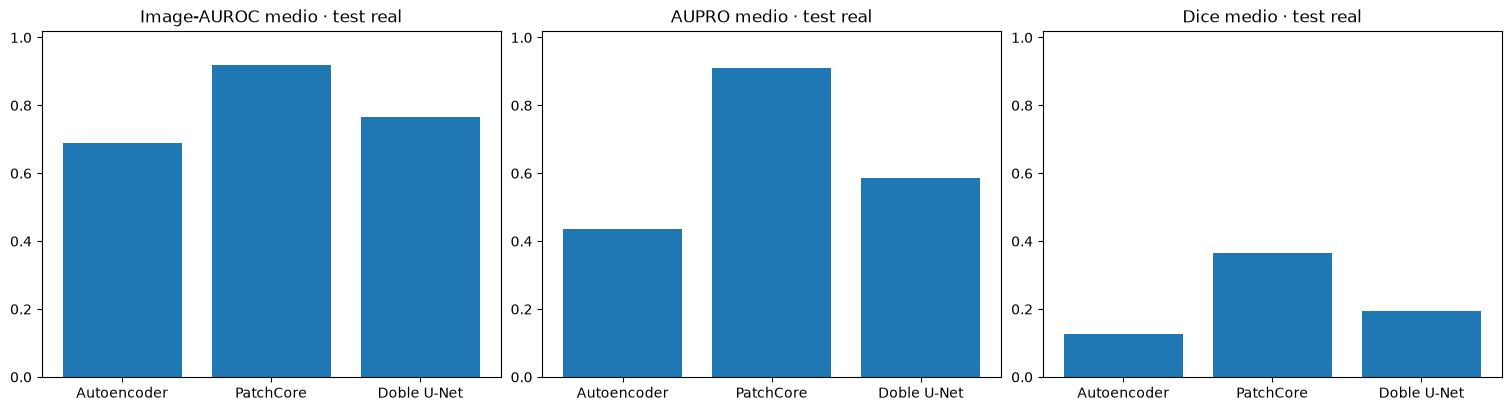

In [7]:
macro=test_df.groupby('model')[['image_auroc_test','aupro_test','dice_test','iou_test','f1_test']].agg(['mean','std']).reindex(MODEL_ORDER)
display(macro.round(3))

fig,axes=plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
for ax,col,name in zip(axes,['image_auroc_test','aupro_test','dice_test'],['Image-AUROC','AUPRO','Dice']):
    values=test_df.groupby('model')[col].mean().reindex(MODEL_ORDER)
    ax.bar([MODEL_NAMES[m] for m in MODEL_ORDER],values)
    ax.set_ylim(0,1.02);ax.set_title(f'{name} medio · test real')

export_figure('test_global_detection_segmentation.png')

for metric in ['image_auroc_test','aupro_test','dice_test']:
    m=test_df.groupby('model')[metric].mean()

PatchCore obtuvo el mejor desempeño en el test real, liderando las tres métricas: Image-AUROC (0.9203), AUPRO (0.9088) y Dice (0.3653). Doble U-Net ocupó el segundo lugar con 0.7655, 0.5865 y 0.1943, respectivamente. Estos resultados evidencian una ventaja de PatchCore tanto en detección como en localización de anomalías

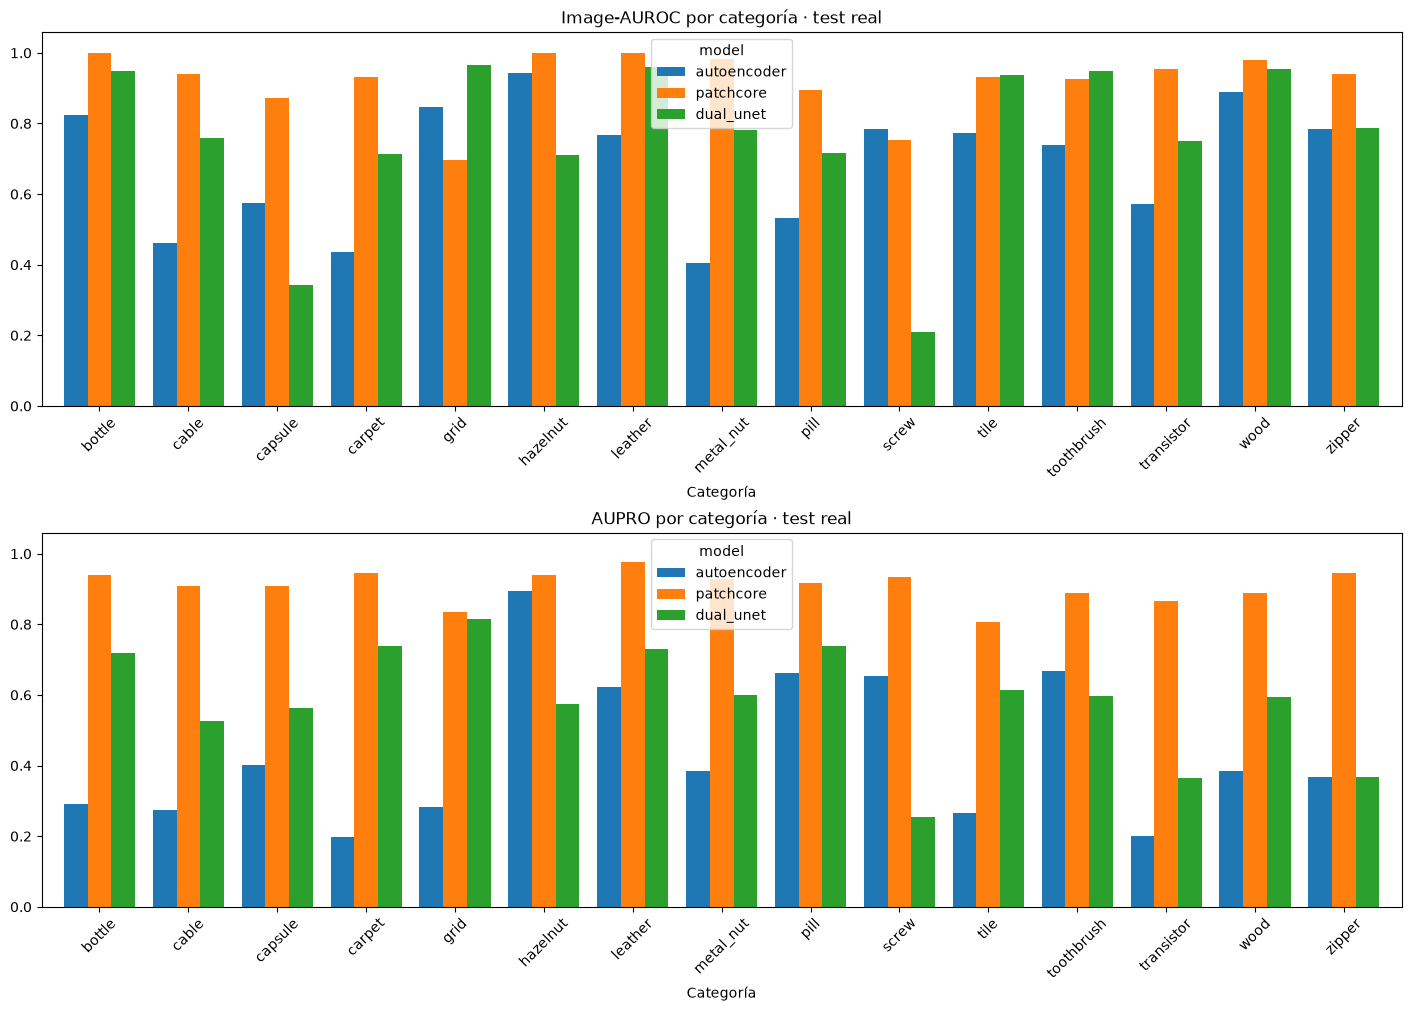

In [9]:
fig,axes=plt.subplots(2,1,figsize=(14,10),constrained_layout=True)
for ax,metric,name in zip(axes,['image_auroc_test','aupro_test'],['Image-AUROC','AUPRO']):
    p=test_df.pivot(index='category',columns='model',values=metric)[MODEL_ORDER].sort_index()
    p.plot.bar(ax=ax,width=.8)
    ax.set_ylim(0,1.06);ax.set_title(f'{name} por categoría · test real')
    ax.tick_params(axis='x',rotation=45);ax.set_xlabel('Categoría')

export_figure('test_by_category.png')

for metric in ['image_auroc_test','aupro_test']:
    p=test_df.pivot(index='category',columns='model',values=metric)
    winners=p.idxmax(axis=1).value_counts()

En Image-AUROC PatchCore lideró en 11 de las 15 categorías, seguido de Doble U-Net con 3 y Autoencoder con 1. En AUPRO PatchCore obtuvo el mejor resultado en las 15 categorías, mostrando una superioridad consistente en localización de anomalías. Aunque el liderazgo por categoría no determina necesariamente el mayor promedio global, ambos análisis favorecen a PatchCore

## Eficiencia y compromisos operativos

Se comparan el tiempo de ajuste, la latencia p95 y los FPS, medidos en el mismo equipo de referencia. El análisis de memoria se limita a los datos registrados y en PatchCore el tiempo de ajuste excluye el preentrenamiento de ResNet18 en ImageNet. Los FPS corresponden únicamente a la inferencia y no representan necesariamente el rendimiento extremo a extremo con cámara y visualización

,fit_seconds,latency_mean_ms,latency_p95_ms,fps
model,,,,
Autoencoder,252.63,2.92,3.50,347.62
PatchCore,8.43,11.68,13.20,88.98
Doble U-Net,547.50,6.86,9.33,149.14


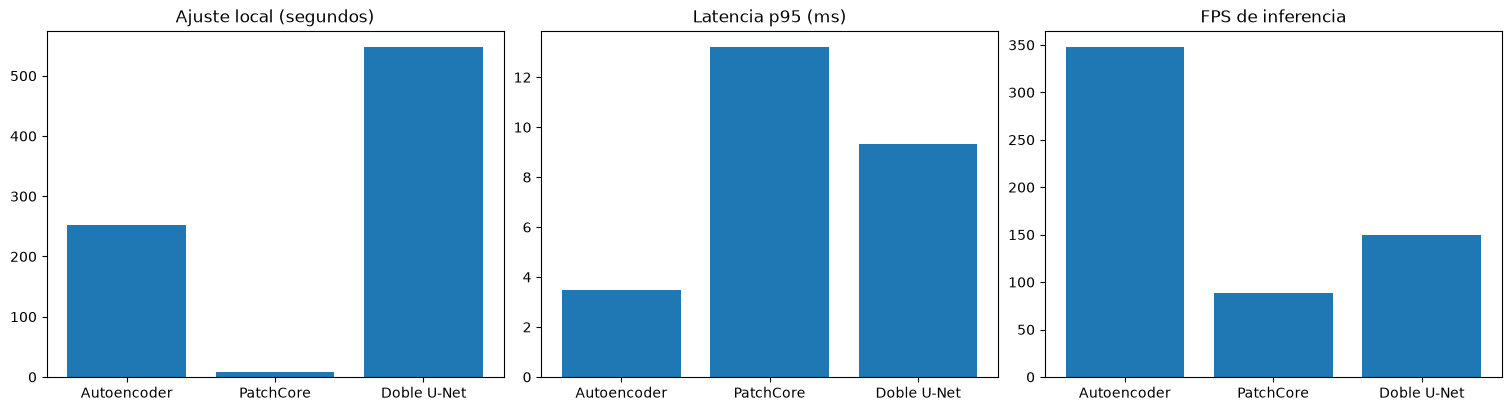

In [11]:
perf=test_df.groupby('model')[['fit_seconds','latency_mean_ms','latency_p95_ms','fps']].mean().reindex(MODEL_ORDER)
display(perf.rename(index=MODEL_NAMES).round(2))

fig,axes=plt.subplots(1,3,figsize=(15,4),constrained_layout=True)
for ax,col,label in zip(axes,['fit_seconds','latency_p95_ms','fps'],['Ajuste local (segundos)','Latencia p95 (ms)','FPS de inferencia']):
    vals=perf[col]
    ax.bar([MODEL_NAMES[m] for m in MODEL_ORDER],vals)
    ax.set_title(label)

export_figure('test_efficiency.png')

PatchCore presentó el menor tiempo de ajuste local, mientras que Autoencoder obtuvo la menor latencia p95. Estos resultados evidencian que un mejor desempeño en detección no implica necesariamente mayor velocidad de inferencia, por lo que la selección del modelo debe equilibrar precisión y eficiencia computacional.

## Generalización: validación sintética frente al test real

Los modelos se seleccionaron mediante validación sintética y se evaluaron con defectos reales. La diferencia en Image-AUROC y AUPRO permite analizar su capacidad de generalización, aunque no determina si las variaciones se deben a diferencias de dominio, características de las perturbaciones sintéticas o tamaño de la muestra

,image_auroc_validation,image_auroc_test,aupro_validation,aupro_test
model,,,,
Autoencoder,0.7116,0.6889,0.4795,0.4367
PatchCore,0.9195,0.9203,0.8699,0.9088
Doble U-Net,0.9698,0.7655,0.9583,0.5865


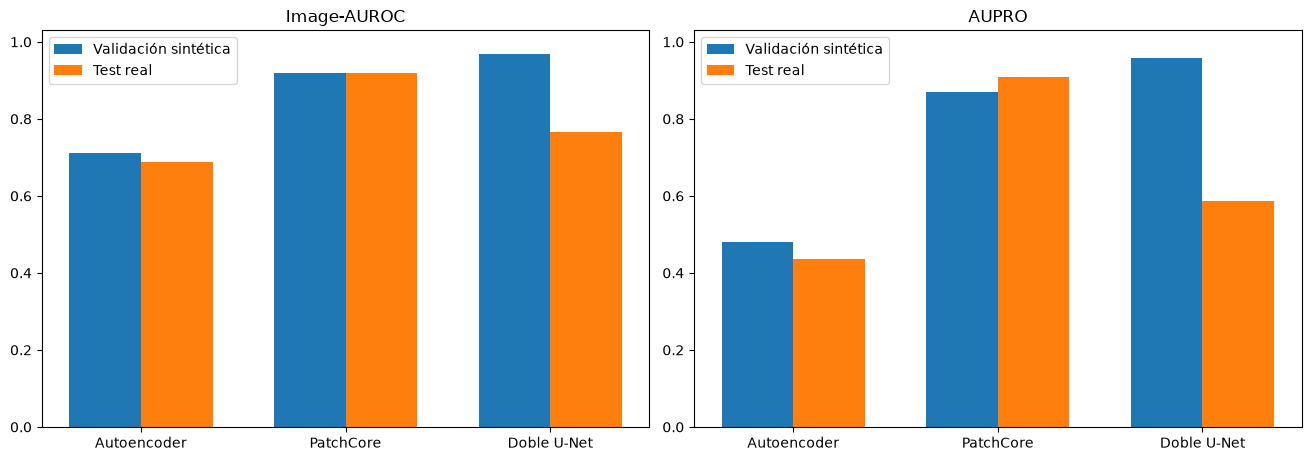

In [13]:
comp = test_df.merge(selected[['category','model','variant','image_auroc','aupro']],on=['category','model','variant'])
comp=comp.rename(columns={'image_auroc':'image_auroc_validation','aupro':'aupro_validation'})
summary=comp.groupby('model')[['image_auroc_validation','image_auroc_test','aupro_validation','aupro_test']].mean().reindex(MODEL_ORDER)
display(summary.rename(index=MODEL_NAMES).round(4))

fig,axes=plt.subplots(1,2,figsize=(13,4.5),constrained_layout=True)

for ax,a,b,label in zip(axes,['image_auroc_validation','aupro_validation'],['image_auroc_test','aupro_test'],['Image-AUROC','AUPRO']):
    xx=np.arange(len(MODEL_ORDER));w=.35
    ax.bar(xx-w/2,summary[a],w,label='Validación sintética')
    ax.bar(xx+w/2,summary[b],w,label='Test real')
    ax.set_xticks(xx,[MODEL_NAMES[m] for m in MODEL_ORDER]);ax.set_ylim(0,1.03);ax.set_title(label)
    ax.legend()
export_figure('validation_vs_real_test.png')

for model in MODEL_ORDER:
    r=summary.loc[model]

La comparación entre validación sintética y test real evidencia diferencias importantes en la capacidad de generalización:

* Autoencoder: presenta una reducción moderada en Image-AUROC (−0.0226) y AUPRO (−0.0428).
* PatchCore: mantiene un desempeño estable en Image-AUROC (+0.0008) y mejora en AUPRO (+0.0389).
* Doble U-Net: registra la mayor caída en Image-AUROC (−0.2043) y AUPRO (−0.3718), lo que sugiere una dependencia importante de las anomalías sintéticas.

PatchCore muestra la mayor consistencia entre ambos conjuntos

## Errores de clasificación y calibración de umbrales

La precisión, el recall y el F1 se calculan utilizando umbrales definidos en validación, sin ajustarlos con el test real. Las matrices de confusión permiten identificar falsos positivos y negativos, así como modelos que clasifican excesivamente las imágenes como defectuosas, incluso cuando presentan un AUROC elevado

,tn,fp,fn,tp
model,,,,
Autoencoder,156,311,413,845
PatchCore,340,127,299,959
Doble U-Net,415,52,657,601


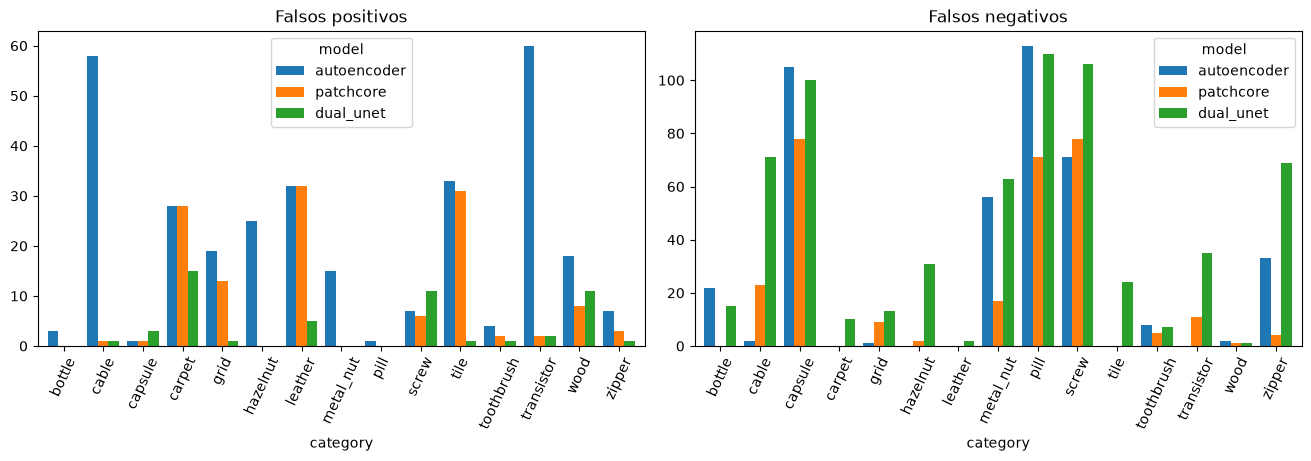

In [15]:
err=test_df.groupby('model')[['tn','fp','fn','tp']].sum().reindex(MODEL_ORDER)
display(err.rename(index=MODEL_NAMES))

fig,axes=plt.subplots(1,2,figsize=(13,4.5),constrained_layout=True)
for ax,col in zip(axes,['fp','fn']):
    p=test_df.pivot(index='category',columns='model',values=col)[MODEL_ORDER].sort_index()
    p.plot.bar(ax=ax,width=.8)
    ax.tick_params(axis='x',rotation=65);ax.set_title('Falsos positivos' if col=='fp' else 'Falsos negativos')

export_figure('test_classification_errors.png')

PatchCore presenta el mejor equilibrio entre falsos positivos y falsos negativos, mientras que Autoencoder genera más falsas alarmas y Doble U-Net omite una proporción elevada de defectos reales

En un contexto industrial, los falsos negativos son especialmente relevantes porque representan defectos que el modelo no detecta. Por ello, PatchCore es la mejor alternativa entre los modelos evaluados, aunque todavía requiere mejorar su sensibilidad en determinadas categorías

## H4 — Comparación entre enfoques en test real

Se compara PatchCore con Autoencoder y Doble U-Net mediante Image-AUROC y AUPRO en las mismas 15 categorías. Se aplica bootstrap sobre las diferencias de desempeño por categoría para estimar intervalos de confianza y la prueba de Wilcoxon para explorar la significancia estadística. Los resultados reflejan la variabilidad entre categorías del benchmark, sin corregir posibles sesgos de selección. Los valores p se interpretan de forma exploratoria

La prueba de Wilcoxon se utiliza para determinar si las diferencias de desempeño entre dos modelos, evaluados sobre las mismas 15 categorías, son sistemáticas o podrían explicarse por la variabilidad de los resultados. Permite complementar la comparación de métricas promedio con evidencia estadística, sin asumir una distribución normal de las diferencias

In [18]:
rng=np.random.default_rng(1926)

def bootstrap_paired_ci(differences,replications=10000):
    values=np.asarray(differences,dtype=float)
    draws=rng.choice(values,size=(replications,len(values)),replace=True).mean(axis=1)
    return tuple(np.quantile(draws,[.025,.975]))

paired=[]
for metric in ['image_auroc_test','aupro_test','dice_test']:
    pivot=test_df.pivot(index='category',columns='model',values=metric)
    for other in ['autoencoder','dual_unet']:
        dif=pivot['patchcore']-pivot[other]
        lo,hi=bootstrap_paired_ci(dif)
        pval=float(wilcoxon(dif).pvalue) if not np.allclose(dif,0) else np.nan
        paired.append({'metric':metric,'comparison':'PatchCore − '+MODEL_NAMES[other],
           'mean_difference':dif.mean(),'ci95_low':lo,'ci95_high':hi,
           'wins':int((dif>1e-10).sum()),'ties':int((abs(dif)<=1e-10).sum()),
           'wilcoxon_p_exploratory':pval})

paired_df=pd.DataFrame(paired)
display(paired_df.round(4))
paired_df.to_csv(TABLE_DIR/'h4_paired_test_comparisons.csv',index=False)

,metric,comparison,mean_difference,ci95_low,ci95_high,wins,ties,wilcoxon_p_exploratory
0,image_auroc_test,PatchCore − Autoencoder,0.2314,0.1320,0.3321,13,0,0.0006
1,image_auroc_test,PatchCore − Doble U-Net,0.1548,0.0533,0.2582,12,0,0.0084
2,aupro_test,PatchCore − Autoencoder,0.4721,0.3714,0.5635,15,0,0.0001
3,aupro_test,PatchCore − Doble U-Net,0.3222,0.2438,0.4049,15,0,0.0001
4,dice_test,PatchCore − Autoencoder,0.2401,0.1465,0.3271,13,0,0.0006
5,dice_test,PatchCore − Doble U-Net,0.1710,0.0957,0.2557,14,0,0.0002


Los resultados del test real muestran una ventaja consistente de PatchCore frente a Autoencoder y Doble U-Net en las tres métricas evaluadas:

* Image-AUROC: PatchCore supera a Autoencoder en 13 de 15 categorías, con una diferencia media de +0.2314 (IC 95 % [0.1320, 0.3321]), y a Doble U-Net en 12 categorías, con +0.1548 (IC 95 % [0.0533, 0.2582]).
* AUPRO: PatchCore obtiene mejores resultados en las 15 categorías frente a ambos modelos. La ventaja media es de +0.4721 respecto a Autoencoder (IC 95 % [0.3714, 0.5635]) y +0.3222 frente a Doble U-Net (IC 95 % [0.2438, 0.4049]).
* Dice: PatchCore supera a Autoencoder en 13 categorías, con una diferencia media de +0.2401 (IC 95 % [0.1465, 0.3271]), y a Doble U-Net en 14 categorías, con +0.1710 (IC 95 % [0.0957, 0.2557]).

PatchCore presenta el mejor desempeño en detección y localización de anomalías. Los intervalos bootstrap respaldan la consistencia de estas diferencias entre las categorías evaluadas, aunque su interpretación es exploratoria y no garantiza la generalización a otros entornos industriales

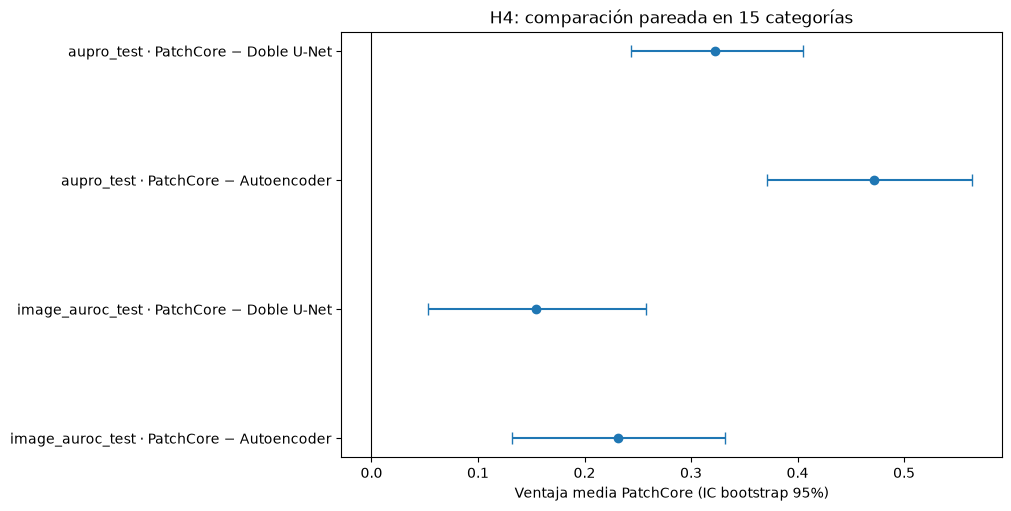

In [20]:
fig,ax=plt.subplots(figsize=(10,5),constrained_layout=True)
p = paired_df[paired_df.metric.isin(['image_auroc_test','aupro_test'])].reset_index(drop=True)
labels=[f"{r['metric']} · {r['comparison']}" for _,r in p.iterrows()]
y=np.arange(len(p))
ax.errorbar(p.mean_difference,y,xerr=[p.mean_difference-p.ci95_low,p.ci95_high-p.mean_difference],fmt='o',capsize=4)
ax.axvline(0,color='black',lw=.8)
ax.set_yticks(y,labels);ax.set_xlabel('Ventaja media PatchCore (IC bootstrap 95%)')
ax.set_title('H4: comparación pareada en 15 categorías')
export_figure('h4_paired_bootstrap.png')

Los puntos representan las diferencias medias de desempeño entre modelos en el test real, mientras que los intervalos de confianza reflejan su incertidumbre. Cuando un intervalo no incluye el cero, existe evidencia de una diferencia sistemática entre modelos. Sin embargo, los resultados deben interpretarse considerando la magnitud de las diferencias y las limitaciones del benchmark

El gráfico muestra que PatchCore supera a Autoencoder y Doble U-Net en detección (Image-AUROC) y localización (AUPRO) sobre las 15 categorías del test real.

* Detección (Image-AUROC): PatchCore obtiene una ventaja media de 0.2314 frente a Autoencoder y 0.1548 frente a Doble U-Net.
* Localización (AUPRO): la ventaja es aún mayor, con diferencias medias de 0.4721 frente a Autoencoder y 0.3222 frente a Doble U-Net.
* Intervalos de confianza: los cuatro intervalos bootstrap del 95 % se encuentran completamente por encima de cero. Esto respalda una ventaja consistente de PatchCore en las categorías evaluadas, aunque no garantiza su superioridad en otros conjuntos de datos.

PatchCore presenta una ventaja clara frente a los otros dos modelos, especialmente en la localización de anomalías. Los intervalos de confianza respaldan que las diferencias observadas no se limitan a pequeñas variaciones del promedio entre categorías. Sin embargo, la evidencia corresponde a las 15 categorías de MVTec AD y debe interpretarse de manera exploratoria, sin asumir que estos resultados se generalizan a otros entornos industriales

## Elección del modelo y conclusiones de investigación

La selección del mejor modelo prioriza Image-AUROC y AUPRO del test real como métricas principales de calidad, considerando la latencia p95, los FPS y el tiempo de ajuste para evaluar su viabilidad operativa

In [22]:
quality = test_df.groupby('model')[['image_auroc_test','aupro_test','dice_test','fit_seconds','latency_p95_ms']].mean()
best_auc = quality.image_auroc_test.idxmax();best_aupro = quality.aupro_test.idxmax()
fastest = quality.latency_p95_ms.idxmin();cheapest = quality.fit_seconds.idxmin()

print('DECISIÓN DOCUMENTADA')
print(f'Mayor Image-AUROC real: {MODEL_NAMES[best_auc]} ({quality.loc[best_auc,"image_auroc_test"]:.4f})')
print(f'Mayor AUPRO real: {MODEL_NAMES[best_aupro]} ({quality.loc[best_aupro,"aupro_test"]:.4f})')
print(f'Menor ajuste local: {MODEL_NAMES[cheapest]} ({quality.loc[cheapest,"fit_seconds"]:.2f} s)')
print(f'Menor latencia p95: {MODEL_NAMES[fastest]} ({quality.loc[fastest,"latency_p95_ms"]:.2f} ms)')

DECISIÓN DOCUMENTADA
Mayor Image-AUROC real: PatchCore (0.9203)
Mayor AUPRO real: PatchCore (0.9088)
Menor ajuste local: PatchCore (8.43 s)
Menor latencia p95: Autoencoder (3.50 ms)


PatchCore se selecciona como el mejor modelo para detectar y localizar anomalías en MVTec AD al obtener los mayores Image-AUROC y AUPRO en el test oficial. Sin embargo, Autoencoder presenta una menor latencia de inferencia, por lo que podría ser preferible en aplicaciones donde la velocidad sea prioritaria

* H1–H3: se evaluaron las dos variantes de cada modelo mediante validación sintética. El test real se aplicó únicamente a las variantes seleccionadas

* H4: se contrastaron los tres modelos sobre las mismas 15 categorías del test real, considerando diferencias de desempeño y eficiencia computacional